In [1]:
import numpy as np
import pandas as pd

runs = pd.read_csv("../data/runs_clean.csv", parse_dates=["date"])
print(runs.shape)
print(runs.columns.tolist())

(269, 8)
['date', 'distance_km', 'elapsed_sec', 'pace', 'days_since_last_run', 'km_last_7d', 'hour', 'day_of_week']


In [2]:
# determining what a good run is
split = int(len(runs) * 0.8)

runs["run_type"] = pd.cut(runs["distance_km"], bins=[0, 8, 12, 100], labels=["easy", "steady", "long"])

usual_pace = runs[:split].groupby("run_type", observed=True)["pace"].median()
print(usual_pace.round(2))

runs["usual_pace"] = runs["run_type"].map(usual_pace).astype(float)
runs["good_run"] = (runs["pace"] < runs["usual_pace"]).astype(int)

print(runs[["distance_km", "run_type", "pace", "usual_pace", "good_run"]].head().round(2))
print(runs["good_run"].value_counts())



run_type
easy      5.65
steady    6.06
long      6.63
Name: pace, dtype: float64
   distance_km run_type  pace  usual_pace  good_run
0        10.17   steady  4.94        6.06         1
1        11.42   steady  5.84        6.06         1
2         6.42     easy  5.83        5.65         0
3         9.85   steady  6.22        6.06         0
4        13.28     long  5.61        6.63         1
good_run
0    142
1    127
Name: count, dtype: int64


In [3]:
features = ["distance_km", "days_since_last_run", "km_last_7d", "hour", "day_of_week"]

X = runs[features].to_numpy()
y = runs["good_run"].to_numpy()

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

mu = X_train.mean(axis=0)
sigma = X_train.std(axis=0)

X_train = (X_train - mu) / sigma
X_test = (X_test - mu) / sigma 

print(X_train.shape, X_test.shape)
print("mu:   ", mu.round(2))
print("sigma:", sigma.round(2))

(215, 5) (54, 5)
mu:    [ 9.51  2.3  19.88 12.51  3.33]
sigma: [4.07 1.29 9.24 5.54 2.06]


In [4]:
# sigmoid function 
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

print(sigmoid(0))
print(sigmoid(4), sigmoid(-4))
print(sigmoid(np.array([-2, 0, 2])))


0.5
0.9820137900379085 0.01798620996209156
[0.11920292 0.5        0.88079708]


In [5]:
# the model 
def predict_proba(X, w, b): 
    z = X @ w + b
    return sigmoid(z)

w = np.zeros(X_train.shape[1])
b = 0.0

print(predict_proba(X_train[:3], w, b))

[0.5 0.5 0.5]


In [6]:
# the cost: log loss
def compute_cost(X, y, w ,b):
    m = len(y)
    f = predict_proba(X, w, b)
    loss = -y * np.log(f) - (1 - y) * np.log(1 - f)
    return loss.sum() / m

print(compute_cost(X_train, y_train, w, b))

0.6931471805599453


In [7]:
# direction for gradient descent
def compute_gradients(X, y, w, b):
    m = len(y)
    f = predict_proba(X, w, b)
    error = f - y 
    dj_dw = (X.T @ error) / m
    dj_db = error.sum() / m 
    return dj_dw, dj_db

dj_dw, dj_db = compute_gradients(X_train, y_train, w, b)
print(dj_dw.round(4))
print(round(dj_db, 4))

[ 0.0569 -0.1719  0.267  -0.1202 -0.0139]
0.0023


In [8]:
# gradient descent 
def gradient_descent (X, y, alpha, iterations):
    w = np.zeros(X.shape[1])
    b = 0.0
    history = []
    for i in range(iterations):
        dj_dw, dj_db = compute_gradients(X, y, w, b)
        w = w - alpha * dj_dw
        b = b - alpha * dj_db 
        history.append(compute_cost(X, y, w, b))
        if i % 500 == 0:
            print(f"step {i:4d}   cost {history[-1]:.4f}")
    return w, b, history

w, b, history = gradient_descent(X_train, y_train, alpha=0.1, iterations=3000)

print("final cost:", round(history[-1],4))
print("w:", w.round(3))
print("b:", round(b, 3))



step    0   cost 0.6815
step  500   cost 0.4852
step 1000   cost 0.4852
step 1500   cost 0.4852
step 2000   cost 0.4852
step 2500   cost 0.4852
final cost: 0.4852
w: [-0.206  0.682 -1.44   0.281 -0.082]
b: -0.037


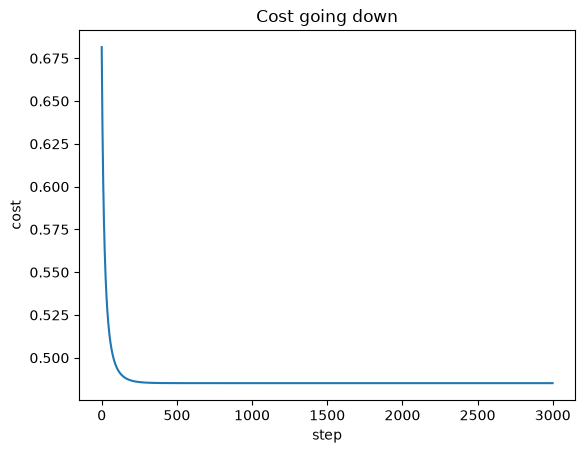

In [9]:
# gradient descent as a chart
import matplotlib.pyplot as plt 

plt.plot(history)
plt.xlabel("step")
plt.ylabel("cost")
plt.title("Cost going down")
plt.savefig("../cost_curve.png", dpi=150)
plt.show()

In [12]:
def predict(X, w, b):
    return(predict_proba(X, w, b) >= 0.5).astype(int)

train_acc = (predict(X_train, w, b) == y_train).mean()
test_acc = (predict(X_test, w, b) == y_test).mean()
baseline = max(y_test.mean(), 1 - y_test.mean())

print("train_accuracy:", round(train_acc, 3))
print("test_accuracy : ", round(test_acc , 3))
print("baseline:       ", round(baseline, 3))

train_accuracy: 0.795
test_accuracy :  0.741
baseline:        0.63


In [13]:
# where it gets it wrong
preds = predict(X_test, w, b)

print("said good, was good:", ((preds == 1) & (y_test == 1)).sum())
print("said good, was bad:", ((preds == 1) & (y_test == 0)).sum())
print("said bad, was good:", ((preds == 0) & (y_test == 1)).sum())
print("said bad, was bad:", ((preds == 0) & (y_test == 0)).sum())



said good, was good: 12
said good, was bad: 6
said bad, was good: 8
said bad, was bad: 28


In [14]:
# what did it learn
for name, weight in zip(features, w):
    print(f"{name:22s} {weight:+3f}")

distance_km            -0.206230
days_since_last_run    +0.682116
km_last_7d             -1.440233
hour                   +0.280893
day_of_week            -0.082448


In [19]:
# double checking my work with scikit
from sklearn.linear_model import LogisticRegression 

sk = LogisticRegression(C=1e6)
sk.fit(X_train, y_train)

print("mine:   ", w.round(3), round(b, 3))
print("sklearn:", sk.coef_[0].round(3), sk.intercept_[0].round(3))
print("sklearn test accuracy:", round(sk.score(X_test, y_test), 3)) 

mine:    [-0.206  0.682 -1.44   0.281 -0.082] -0.037
sklearn: [-0.206  0.682 -1.44   0.281 -0.082] -0.037
sklearn test accuracy: 0.741


In [22]:
# regularization 
def compute_gradients_reg(X, y, w, b, lam):
    m = len(y)
    dj_dw, dj_db = compute_gradients(X, y, w, b)
    dj_dw = dj_dw + (lam / m) * w
    return dj_db, dj_db

def gradient_descent_reg (X, y, alpha, iterations, lam):
    w = np.zeros(X.shape[1])
    b = 0.0
    for i in range(iterations):
        dj_dw, dj_db = compute_gradients_reg(X, y, w, b, lam)
        w = w - alpha * dj_dw
        b = b - alpha * dj_db
    return w, b

for lam in [0, 1, 10, 100, 1000]:
    w_r, b_r = gradient_descent_reg(X_train, y_train, 0.1, 3000, lam)
    acc = (predict(X_test, w_r, b_r) == y_test).mean()
    cost = compute_cost(X_test, y_test, w_r, b_r)
    print(f"lambda={lam:<5} accuracy={acc:.3f}   test cost={cost:.3f}")

lambda=0     accuracy=0.519   test cost=0.693
lambda=1     accuracy=0.519   test cost=0.693
lambda=10    accuracy=0.519   test cost=0.693
lambda=100   accuracy=0.519   test cost=0.693
lambda=1000  accuracy=0.519   test cost=0.693


In [23]:
# regularization with scikit
w_1, b_1 = gradient_descent_reg(X_train, y_train, 0.1, 3000, 1)
sk_1 = LogisticRegression(C=1.0).fit(X_train, y_train)

print("mine, lambda=1:", w_1.round(3))
print("sklearn, C=1:   ", sk_1.coef_[0].round(3))

mine, lambda=1: [-0.009 -0.009 -0.009 -0.009 -0.009]
sklearn, C=1:    [-0.202  0.647 -1.361  0.276 -0.075]
